# Benchmark 2: S-Shaped Bifurcation

S-shaped bifurcation normal form:
$$\dot{u} = f(u, \mu) = -u^3 + u + \mu$$

1. Oscillating roots vs. branch-approximating solutions by degree continuation.
2. Uniqueness and exponential convergence on $I = [0.5, 1.5]$.
3. Disconnected branches and fold on $I = [0, 0.4]$.

In [5]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style, plot_roots_vs_branches, plot_regime

set_plot_style(usetex=True)

mu_sn = 2.0 / (3.0 * np.sqrt(3.0))

def rhs(u, mu):
    return -u**3 + u + mu[None, :]

def jac(u, mu):
    return (-3.0 * u**2 + 1.0)[None, :, :]

def exact_unique(mu):
    """Unique real root for |mu| > 2 / (3*sqrt(3)) via Cardano's formula."""
    s = np.sqrt(0.25 * mu**2 - 1.0 / 27.0)
    return (np.cbrt(0.5 * mu + s) + np.cbrt(0.5 * mu - s))[None, :]

## 1. Oscillating roots and degree continuation

Direct root-finding at $N = 10$ from random initial guesses on $I = [-0.15, 0.3]$ produces spurious oscillating solutions, while degree continuation isolates all three physical branches.

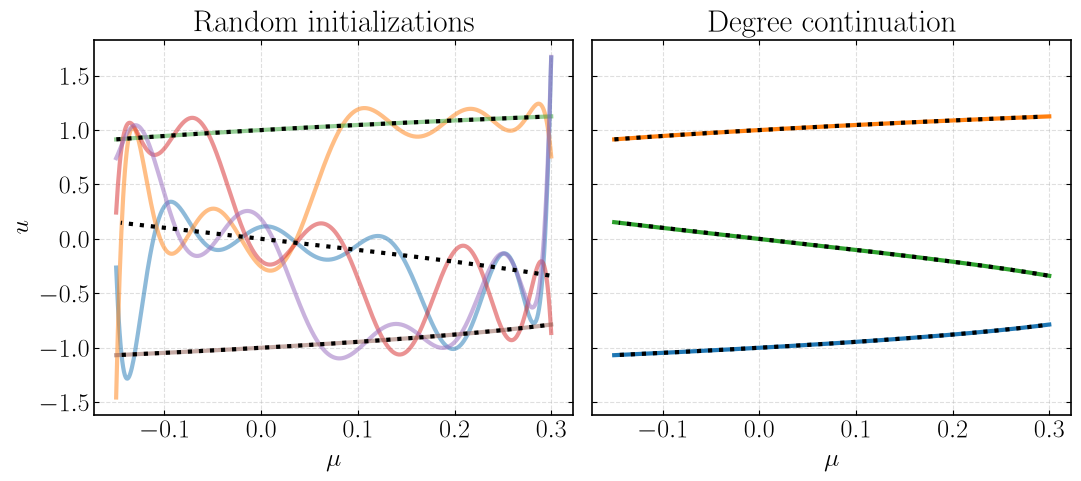

In [6]:
mu_bounds = (-0.15, 0.3)
u_ex = np.linspace(-1.3, 1.3, 500)
mu_ex = u_ex**3 - u_ex
u_plot = np.where((mu_ex >= mu_bounds[0]) & (mu_ex <= mu_bounds[1]), u_ex, np.nan)

plot_roots_vs_branches(
    rhs,
    jac,
    mu_bounds=mu_bounds,
    exact_curves=[(mu_ex, u_plot)],
    N=10,
    n_samples=30,
    seed=2,
    scale=0.8,
    box=(-1.5, 1.5),
)

## 2. Uniqueness and convergence

On $I = [0.5, 1.5]$, after the fold in $\mu_+=\frac{2}{3\sqrt{3}}$, the system admits a unique analytical branch $\bar{u}(\mu)$ and satisfies the global uniqueness hypotheses, yielding exponential convergence to machine precision.

Estimated rho (linf): 5.9226


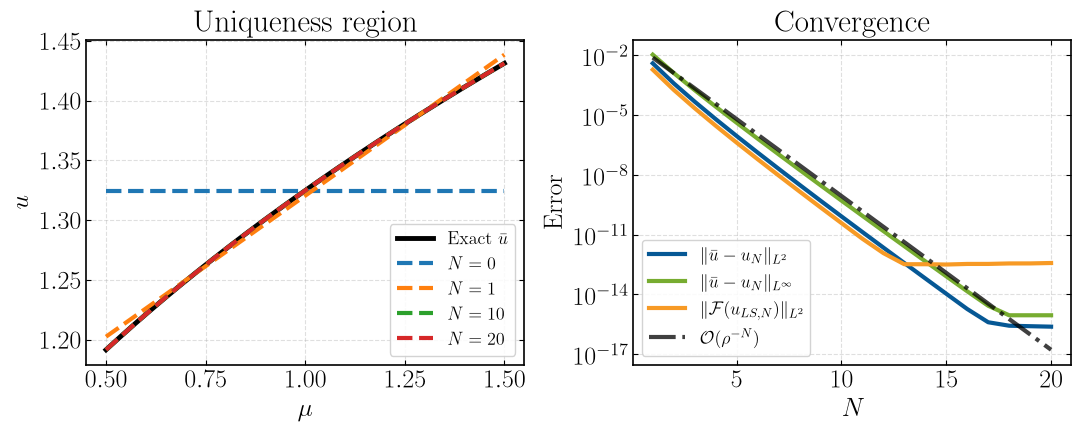

In [7]:
plot_regime(rhs, jac, exact_unique, "Uniqueness region", bounds=(0.5, 1.5),
            ref_rates=[(r"$\mathcal{O}(\rho^{-N})$", "-.", None, "linf")],
            u0=[1.2], N_max=20)

## 3. Disconnected branches and fold

When an interval contains a saddle-node fold, degree continuation can extrapolate the partially supported branches only up to a finite degree before failing, leaving only the globally supported branch.

N=0: 3/3 branches converged
N=4: 3/3 branches converged
N=5: 1/3 branches converged


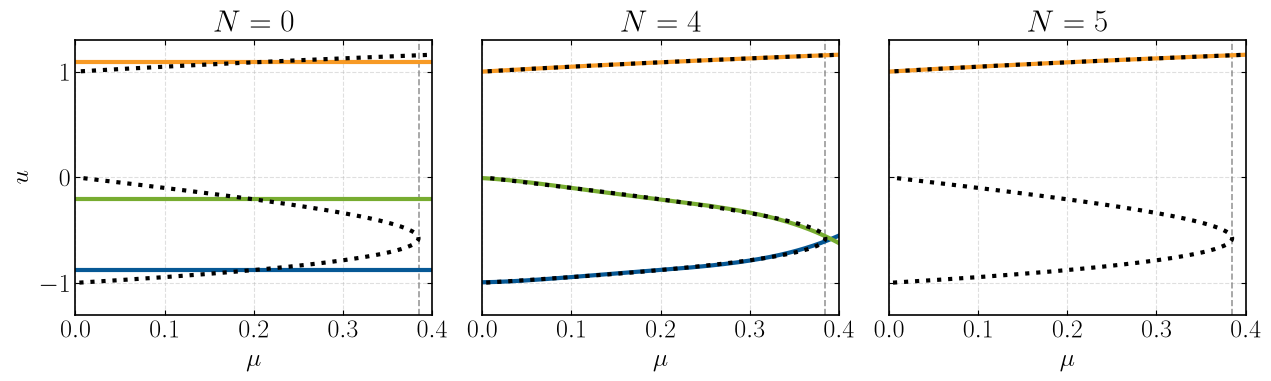

In [13]:
def plot_disconnected_branches(bounds, u0_list, N_max=15):
    solver = PCEGalerkin(rhs, jac, mu_bounds=bounds, state_dim=1, quad_order=2 * N_max + 1)
    histories = [
        solver.continuation(N_max, u0=[u0], return_history=True, stop_on_fail=True)
        for u0 in u0_list
    ]

    n_last = min(max(h.keys()) for h in histories if h)
    plot_N = sorted(set([0, n_last, n_last + 1])) if n_last < N_max else [0, N_max // 2, N_max]

    u_bg = np.linspace(-1.3, 1.3, 500)
    mu_bg = u_bg**3 - u_bg
    u_bg_plot = np.where((mu_bg >= bounds[0]) & (mu_bg <= bounds[1]), u_bg, np.nan)

    fig, axes = plt.subplots(1, len(plot_N), figsize=(4.3 * len(plot_N), 4), sharey=True)
    colors = ["#065895", "#77ac30", "#f79a25"]

    for ax, N in zip(axes, plot_N):
        ax.plot(mu_bg, u_bg_plot, "k:", lw=3.0, zorder=5, label="Exact")
        for fold in (-mu_sn, mu_sn):
            if bounds[0] <= fold <= bounds[1]:
                ax.axvline(fold, color="gray", ls="--", lw=1.2, alpha=0.8)

        converged = 0
        for idx, h in enumerate(histories):
            if N in h:
                mu_g, u_g = solver.eval(h[N])
                ax.plot(mu_g, u_g[0], "-", color=colors[idx % len(colors)], zorder=2)
                converged += 1

        print(f"N={N}: {converged}/{len(u0_list)} branches converged")
        ax.set_title(rf"$N = {N}$")
        ax.set_xlabel(r"$\mu$")
        ax.set_xlim(bounds)
        ax.set_ylim(-1.3, 1.3)
        ax.grid(True, linestyle="--", alpha=0.4)

    axes[0].set_ylabel(r"$u$")
    plt.tight_layout()
    plt.show()

plot_disconnected_branches(bounds=(0.0, 0.4), u0_list=[-1.0, -0.2, 1.0])